Experiment: Principal Component Analysis (PCA) 

Aim: Perform dimensionality reduction using PCA, visualize a high-dimensional dataset in 2D space, and compare model performance before and after PCA.

Step 1: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

Step 2: Load the dataset

We use the Breast Cancer dataset from scikit-learn. It has 569 samples and 30 numeric features. The target has two classes: malignant (0) and benign (1). 30 features is too many to plot directly, so this is a good dataset for PCA.

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target

print("Shape of X:", X.shape)
print("Number of features:", X.shape[1])
print("Classes:", data.target_names)
print("Samples in each class:", np.bincount(y))

df = pd.DataFrame(X, columns=data.feature_names)
df.head()

Shape of X: (569, 30)
Number of features: 30
Classes: ['malignant' 'benign']
Samples in each class: [212 357]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Step 3: Split the data and standardize

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train shape:", X_train_s.shape)
print("Test shape:", X_test_s.shape)

Train shape: (426, 30)
Test shape: (143, 30)


Step 4: Apply PCA and check explained variance

First we apply PCA with all 30 components to see how much variance each component explains. The explained variance ratio tells us what fraction of the total information is captured by each component.

In [4]:
pca_full = PCA()
pca_full.fit(X_train_s)

ratio = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratio)

for i in range(10):
    print("PC", i + 1, ": variance =", round(ratio[i], 4), ", cumulative =", round(cumulative[i], 4))

PC 1 : variance = 0.439 , cumulative = 0.439
PC 2 : variance = 0.1952 , cumulative = 0.6341
PC 3 : variance = 0.0941 , cumulative = 0.7282
PC 4 : variance = 0.0679 , cumulative = 0.7961
PC 5 : variance = 0.0558 , cumulative = 0.8519
PC 6 : variance = 0.0401 , cumulative = 0.892
PC 7 : variance = 0.0219 , cumulative = 0.9139
PC 8 : variance = 0.0157 , cumulative = 0.9295
PC 9 : variance = 0.0124 , cumulative = 0.942
PC 10 : variance = 0.0116 , cumulative = 0.9536


Scree plot and cumulative variance plot

The left plot shows the variance explained by each component. The right plot shows the cumulative variance. The dashed line marks 95 percent. We can see that only a few components are needed to capture most of the information.

Components needed for 95 percent variance: 10


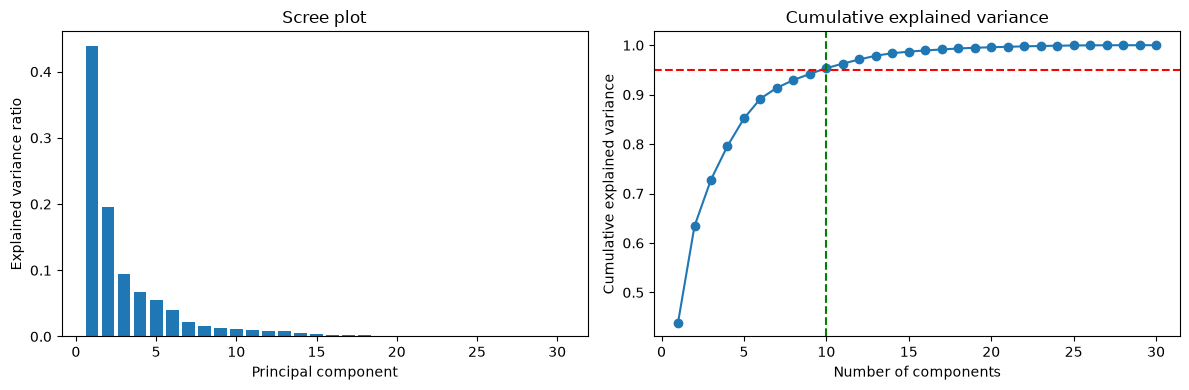

In [5]:
n_95 = np.argmax(cumulative >= 0.95) + 1
print("Components needed for 95 percent variance:", n_95)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.bar(range(1, len(ratio) + 1), ratio)
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("Scree plot")

plt.subplot(1, 2, 2)
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.axhline(0.95, color="red", linestyle="--")
plt.axvline(n_95, color="green", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance")

plt.tight_layout()
plt.show()

Step 5: Visualize the data in 2D

Now we reduce the 30 features to just 2 principal components and plot the data. Each point is a patient. If the two classes appear in separate regions, it means the first two components keep useful information about the classes.

Variance kept by 2 components: 0.6341


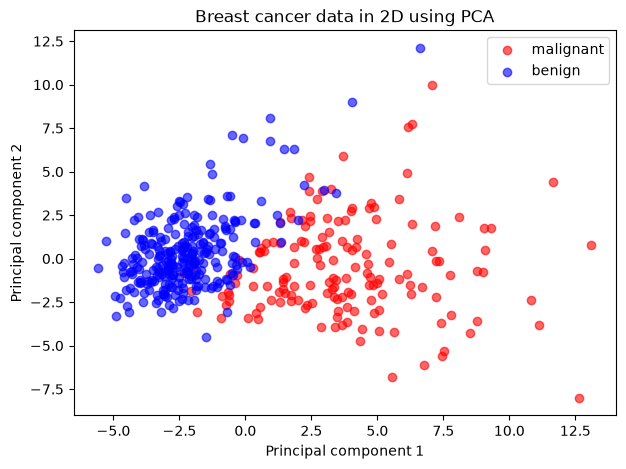

In [6]:
pca2 = PCA(n_components=2)
X_train_2d = pca2.fit_transform(X_train_s)
X_test_2d = pca2.transform(X_test_s)

print("Variance kept by 2 components:", round(pca2.explained_variance_ratio_.sum(), 4))

plt.figure(figsize=(7, 5))
plt.scatter(X_train_2d[y_train == 0, 0], X_train_2d[y_train == 0, 1],
            c="red", label="malignant", alpha=0.6)
plt.scatter(X_train_2d[y_train == 1, 0], X_train_2d[y_train == 1, 1],
            c="blue", label="benign", alpha=0.6)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("Breast cancer data in 2D using PCA")
plt.legend()
plt.show()

Observation: The two classes are mostly separated even though we went from 30 dimensions down to 2. There is some overlap in the middle, which is where a model could make mistakes.

Step 6: Compare model performance before and after PCA

We use two models: Logistic Regression and Random Forest.

In [7]:
pca95 = PCA(n_components=0.95)
X_train_95 = pca95.fit_transform(X_train_s)
X_test_95 = pca95.transform(X_test_s)
print("Components kept for 95 percent variance:", pca95.n_components_)

datasets = {
    "Original (30 features)": (X_train_s, X_test_s),
    "PCA 2 components": (X_train_2d, X_test_2d),
    "PCA 95 percent (" + str(pca95.n_components_) + " components)": (X_train_95, X_test_95),
}

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

rows = []
for data_name, (Xtr, Xte) in datasets.items():
    for model_name, model in models.items():
        model.fit(Xtr, y_train)
        acc = accuracy_score(y_test, model.predict(Xte))
        rows.append([data_name, model_name, Xtr.shape[1], round(acc, 4)])

results = pd.DataFrame(rows, columns=["Data", "Model", "Features", "Test accuracy"])
results

Components kept for 95 percent variance: 10


,Data,Model,Features,Test accuracy
0,Original (30 features),Logistic Regression,30,0.9860
1,Original (30 features),Random Forest,30,0.9580
2,PCA 2 components,Logistic Regression,2,0.9441
3,PCA 2 components,Random Forest,2,0.9441
4,PCA 95 percent (10 components),Logistic Regression,10,0.9790
5,PCA 95 percent (10 components),Random Forest,10,0.9510


The bar chart below shows the same results so they are easy to compare.

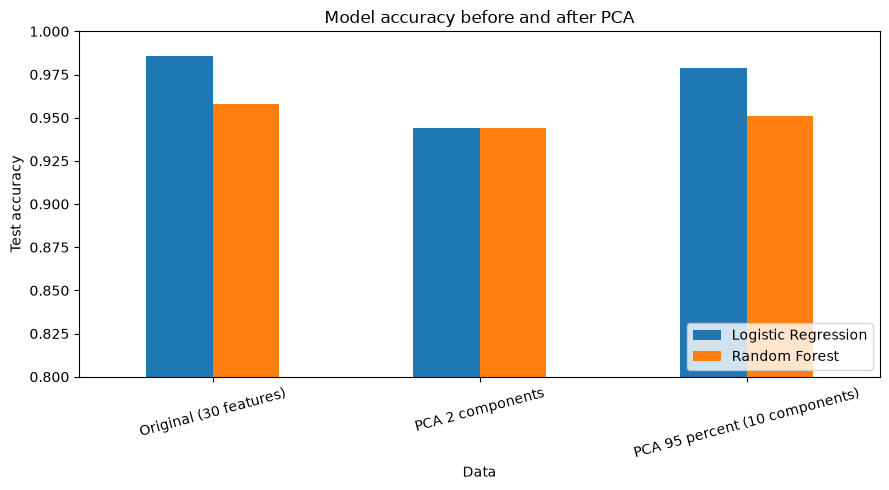

In [8]:
pivot = results.pivot(index="Data", columns="Model", values="Test accuracy")
pivot = pivot.loc[list(datasets.keys())]

pivot.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Test accuracy")
plt.title("Model accuracy before and after PCA")
plt.ylim(0.8, 1.0)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Step 7: Accuracy for different numbers of components

Here we check how the accuracy of Logistic Regression changes as we keep more components. This helps us decide how many components are enough.

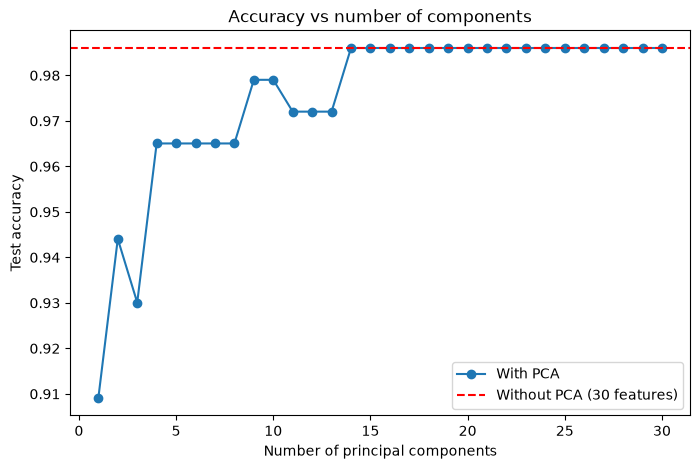

In [9]:
accs = []
ks = range(1, 31)
for k in ks:
    p = PCA(n_components=k)
    Xtr_k = p.fit_transform(X_train_s)
    Xte_k = p.transform(X_test_s)
    m = LogisticRegression(max_iter=1000)
    m.fit(Xtr_k, y_train)
    accs.append(accuracy_score(y_test, m.predict(Xte_k)))

base = accuracy_score(y_test, LogisticRegression(max_iter=1000).fit(X_train_s, y_train).predict(X_test_s))

plt.figure(figsize=(8, 5))
plt.plot(list(ks), accs, marker="o", label="With PCA")
plt.axhline(base, color="red", linestyle="--", label="Without PCA (30 features)")
plt.xlabel("Number of principal components")
plt.ylabel("Test accuracy")
plt.title("Accuracy vs number of components")
plt.legend()
plt.show()

Conclusion

1. PCA reduced the dataset from 30 features to a much smaller number of components while keeping most of the information. About 10 components were enough to keep 95 percent of the variance.
2. With just 2 components we could plot the data in 2D, and the two classes were mostly separable.
3. Model accuracy after PCA with 95 percent variance is very close to the accuracy on the original data, even though far fewer features are used. With only 2 components the accuracy drops slightly because some information is lost.
